# Do semantic IDs help new items? Rebuilding Meta's GenRecs tokenization on MovieLens

Independent rebuild of the idea in Meta's *GenRecs Tokenization* post (Hu, Johnson, Aggarwal, Rangadurai, Manickavelu, Zhang, Oct 2026),
using the public recipe it builds on: semantic IDs with prefix n-grams (Singh et al. 2023, [arXiv 2306.08121](https://arxiv.org/abs/2306.08121)).
Hypotheses and pass/fail rules were committed before any model was trained (`PREREGISTRATION.md`).

**Assumptions** (numbered, used throughout)
1. Real data: about 857,000 MovieLens ratings on the 4,560 movies with at least 10 ratings. Target: liked (rating >= 4) or not, a stand-in for a click or conversion label.
2. Content signal: CLIP ViT-B/32 (laion2b) text embedding of "title. genres". No images, so this is a text-only version of Meta's multimodal encoder.
3. Cold items: 20% of movies, drawn within popularity deciles, never seen in training. Warm test: 10% of the other ratings, held out at random.
4. The tokenizer (codebooks) is learned on warm items only. New items are assigned to the nearest codes, as they would be after launch.
5. Every downstream model is the same small PyTorch model, same epochs, same seed. Only the item representation changes.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, os, time, torch
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score

torch.set_num_threads(2); torch.manual_seed(0)
os.makedirs("figures", exist_ok=True)
PARQUET_URL = "https://huggingface.co/datasets/ashraq/movielens_ratings/resolve/main/data/train-00000-of-00001-8c8c7645a52d95e5.parquet"
r = pd.read_parquet("ratings.parquet" if os.path.exists("ratings.parquet") else PARQUET_URL)
cnt = r.groupby("movie_id").size()
r = r[r.movie_id.isin(cnt[cnt >= 10].index)].copy()
items = np.sort(r.movie_id.unique()); users = np.sort(r.user_id.unique())
iidx = {m: i for i, m in enumerate(items)}; uidx = {u: i for i, u in enumerate(users)}
r["i"] = r.movie_id.map(iidx); r["u"] = r.user_id.map(uidx); r["y"] = (r.rating >= 4).astype(np.float32)
meta = r.drop_duplicates("i").set_index("i").sort_index()
NI, NU = len(items), len(users)
print(f"{len(r):,} ratings, {NU:,} users, {NI:,} movies, like rate {r.y.mean():.3f}")

# cold items: 20% within popularity deciles
rng = np.random.default_rng(0)
pop = r.groupby("i").size().reindex(range(NI)).values
dec = pd.qcut(np.log(pop), 10, labels=False)
cold = np.zeros(NI, bool)
for k in range(10):
    ids = np.where(dec == k)[0]; cold[rng.choice(ids, int(round(0.2 * len(ids))), replace=False)] = True
r["cold"] = cold[r.i.values]
warm_r = r[~r.cold]
test_mask = rng.random(len(warm_r)) < 0.10
TRAIN, WTEST, CTEST = warm_r[~test_mask], warm_r[test_mask], r[r.cold]
HEAD = np.zeros(NI, bool); wpop = pd.Series(pop)[~cold]; HEAD[wpop[wpop >= wpop.quantile(0.9)].index] = True
print(f"train {len(TRAIN):,}  warm test {len(WTEST):,}  cold test {len(CTEST):,}  cold movies {cold.sum()}")

857,323 ratings, 43,542 users, 4,560 movies, like rate 0.495


train 605,477  warm test 67,409  cold test 184,437  cold movies 911


## Item signals: content (CLIP text) and engagement (SVD on training likes only)

In [2]:
if os.path.exists("clip_text.npy"):
    CONTENT = np.load("clip_text.npy")
else:
    import open_clip
    model, _, _ = open_clip.create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k")
    tok = open_clip.get_tokenizer("ViT-B-32"); model.eval()
    texts = [f"{t}. {g.replace('|', ', ')}" for t, g in zip(meta.title, meta.genres)]
    embs = []
    with torch.no_grad():
        for b in range(0, NI, 256):
            e = model.encode_text(tok(texts[b:b + 256])); embs.append((e / e.norm(dim=1, keepdim=True)).numpy())
    CONTENT = np.vstack(embs).astype(np.float32); np.save("clip_text.npy", CONTENT)
CONTENT = CONTENT - CONTENT[~cold].mean(0)          # center (the cone effect from the MAPS rebuild)
CONTENT /= np.linalg.norm(CONTENT, axis=1, keepdims=True)

L = csr_matrix((TRAIN.y.values, (TRAIN.u.values, TRAIN.i.values)), shape=(NU, NI))
_, s_, vt = svds(L, k=32, random_state=0)   # seeded: ARPACK's start vector is random otherwise
ENG = (vt.T * np.sqrt(s_)).astype(np.float32)        # zero rows for cold items (no training data)
ENG_n = ENG / (np.linalg.norm(ENG, axis=1, keepdims=True) + 1e-9)
ridge = Ridge(alpha=1.0).fit(CONTENT[~cold], ENG_n[~cold])
ALIGNED = ridge.predict(CONTENT).astype(np.float32)   # content mapped into engagement space, for every item
ALIGNED /= np.linalg.norm(ALIGNED, axis=1, keepdims=True) + 1e-9
print("ridge R2 on warm items (in sample):", round(ridge.score(CONTENT[~cold], ENG_n[~cold]), 3))

ridge R2 on warm items (in sample): 0.283


## Tokenizers: residual k-means, 3 levels
Each level clusters what the previous level left unexplained. An item's semantic ID is its 3 codes, for example (12, 3, 40).
Twelve versions: three inputs (content, engagement-aligned, both) times three codebook sizes, plus three weak baselines.

In [3]:
def rq_kmeans(X, K, levels=3, seed=0):
    """Fit on warm items, assign every item. Returns codes (NI x levels)."""
    codes = np.zeros((NI, levels), int); R = X.copy()
    for l in range(levels):
        km = KMeans(K, n_init=3, random_state=seed + l).fit(R[~cold])
        c = km.predict(R); codes[:, l] = c; R = R - km.cluster_centers_[c]
    return codes

def random_proj_codes(X, K, levels=3, seed=0):
    """Weak baseline: k-means on a random 4-dim projection at each level (throws most of the signal away)."""
    rs = np.random.default_rng(seed); codes = np.zeros((NI, levels), int)
    for l in range(levels):
        P = X @ rs.normal(size=(X.shape[1], 4))
        codes[:, l] = KMeans(K, n_init=3, random_state=seed + l).fit(P[~cold]).predict(P)
    return codes

FUSED = np.hstack([CONTENT @ np.linalg.svd(CONTENT[~cold], full_matrices=False)[2][:32].T, ALIGNED])
FUSED /= np.linalg.norm(FUSED, axis=1, keepdims=True)
TOK = {}
for K in [8, 32, 128]:
    TOK[f"content_K{K}"] = rq_kmeans(CONTENT, K)
    TOK[f"aligned_K{K}"] = rq_kmeans(ALIGNED, K)
    TOK[f"fused_K{K}"] = rq_kmeans(FUSED, K)
TOK["randproj_K32"] = random_proj_codes(CONTENT, 32)
TOK["randproj_K128"] = random_proj_codes(CONTENT, 128, seed=5)
TOK["random_K32"] = np.random.default_rng(9).integers(0, 32, (NI, 3))

PRIM = meta.genres.str.split("|").str[0].values
def intrinsic(codes):
    """Cluster purity (majority primary genre within each 2-level prefix, weighted), distribution balance
    (normalized entropy of full-code counts), codebook utilization (share of codes used, averaged over levels). Warm items."""
    w = ~cold
    pref = pd.Series([f"{a}-{b}" for a, b in codes[w, :2]])
    g = pd.DataFrame({"p": pref, "g": PRIM[w]})
    purity = g.groupby("p").g.agg(lambda s: s.value_counts().iloc[0]).sum() / w.sum()
    full = pd.Series([tuple(c) for c in codes[w]]).value_counts().values
    ent = -(full / full.sum() * np.log(full / full.sum())).sum() / np.log(w.sum())
    K = codes.max() + 1
    util = np.mean([len(np.unique(codes[w, l])) / K for l in range(codes.shape[1])])
    return dict(purity=float(purity), balance=float(ent), utilization=float(util),
                collision=float(1 - len(full) / w.sum()))
INTR = pd.DataFrame({k: intrinsic(v) for k, v in TOK.items()}).T
print(INTR.round(3).to_string())

               purity  balance  utilization  collision
content_K8      0.653    0.706          1.0      0.870
aligned_K8      0.530    0.718          1.0      0.874
fused_K8        0.657    0.718          1.0      0.868
content_K32     0.793    0.967          1.0      0.173
aligned_K32     0.682    0.983          1.0      0.096
fused_K32       0.801    0.981          1.0      0.108
content_K128    0.900    0.987          1.0      0.071
aligned_K128    0.943    0.999          1.0      0.005
fused_K128      0.960    0.999          1.0      0.007
randproj_K32    0.517    0.984          1.0      0.089
randproj_K128   0.899    0.999          1.0      0.004
random_K32      0.440    0.990          1.0      0.057


## One downstream model, five ways to represent an item
score = global bias + user bias + item bias + user vector . item vector. The item bias and vector come from the representation:
an ID table, a projection of the CLIP vector, or the sum of embeddings for the semantic ID prefixes (c1), (c1, c2), (c1, c2, c3).

In [4]:
def prefix_ids(codes):
    """Map each item's prefix n-grams to integer ids. Returns (NI x 3) ids into one shared table."""
    ids = np.zeros_like(codes); table = {}
    for i in range(NI):
        for l in range(3):
            key = (l,) + tuple(codes[i, :l + 1])
            ids[i, l] = table.setdefault(key, len(table))
    return ids, len(table)

class Model(torch.nn.Module):
    def __init__(self, kind, d=32, sid=None, n_sid=0):
        super().__init__()
        self.kind = kind
        parts = kind.split("+"); self.use_id = "id" in parts; self.use_sid = "sid" in parts
        self.U = torch.nn.Embedding(NU, d); self.bu = torch.nn.Embedding(NU, 1)
        for m in [self.U, self.bu]: torch.nn.init.normal_(m.weight, 0, 0.01)
        self.b0 = torch.nn.Parameter(torch.zeros(1))
        if self.use_id:
            self.I = torch.nn.Embedding(NI + 1, d + 1); torch.nn.init.normal_(self.I.weight, 0, 0.01)   # last row = unknown item
        if self.use_sid:
            self.S = torch.nn.Embedding(n_sid, d + 1); torch.nn.init.normal_(self.S.weight, 0, 0.01)
            self.register_buffer("sid", torch.tensor(sid))
        if kind == "content":
            self.W = torch.nn.Linear(CONTENT.shape[1], d + 1); self.register_buffer("C", torch.tensor(CONTENT))
    def item(self, i, unknown):
        v = 0
        if self.use_id:
            v = v + self.I(torch.where(unknown, torch.full_like(i, NI), i))
        if self.use_sid:
            v = v + self.S(self.sid[i]).sum(1)
        if self.kind == "content":
            v = v + self.W(self.C[i])
        return v
    def forward(self, u, i, unknown):
        q = self.item(i, unknown)
        return self.b0 + self.bu(u)[:, 0] + q[:, 0] + (self.U(u) * q[:, 1:]).sum(1)

def train_eval(kind, sid=None, n_sid=0, epochs=4, seed=0, return_model=False):
    torch.manual_seed(seed)
    m = Model(kind, sid=sid, n_sid=n_sid)
    opt = torch.optim.Adam(m.parameters(), lr=0.005)
    u = torch.tensor(TRAIN.u.values); i = torch.tensor(TRAIN.i.values); y = torch.tensor(TRAIN.y.values)
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        perm = torch.randperm(len(u), generator=g)
        for b in range(0, len(u), 4096):
            idx = perm[b:b + 4096]
            unk = torch.rand(len(idx), generator=g) < 0.05          # ID dropout teaches the unknown-item row
            loss = torch.nn.functional.binary_cross_entropy_with_logits(m(u[idx], i[idx], unk), y[idx])
            reg = 1e-6 * sum((p ** 2).sum() for n_, p in m.named_parameters() if n_ in ("U.weight", "I.weight", "S.weight"))
            opt.zero_grad(); (loss + reg).backward(); opt.step()
    m.eval(); out = {}
    with torch.no_grad():
        for name, df in [("warm", WTEST), ("cold", CTEST)]:
            uu = torch.tensor(df.u.values); ii = torch.tensor(df.i.values)
            out[name] = m(uu, ii, torch.tensor(cold[df.i.values])).numpy()
    return (out, m) if return_model else out

def auc(df, s): return roc_auc_score(df.y.values, s)

t0 = time.time()
PRED = {}
for kind in ["id", "content"]:
    PRED[kind] = train_eval(kind); print(kind, f"{time.time() - t0:.0f}s", flush=True)
SIDS = {k: prefix_ids(v) for k, v in TOK.items()}
for k, (sid, n) in SIDS.items():
    PRED[f"sid:{k}"] = train_eval("sid", sid, n); print(k, f"{time.time() - t0:.0f}s", flush=True)
BEST_TOK = "fused_K32"
PRED["id+sid"] = train_eval("id+sid", *SIDS[BEST_TOK])
AUC = pd.DataFrame({k: dict(warm=auc(WTEST, v["warm"]), cold=auc(CTEST, v["cold"]),
                            head=auc(WTEST[HEAD[WTEST.i.values]], v["warm"][HEAD[WTEST.i.values]])) for k, v in PRED.items()}).T
print(AUC.round(4).to_string())

id 40s


content 112s


content_K8 171s


aligned_K8 241s


fused_K8 297s


content_K32 363s


... (5 outputs left out)

randproj_K32 651s


randproj_K128 713s


random_K32 766s


                     warm    cold    head
id                 0.8072  0.7496  0.7963
content            0.7783  0.7529  0.7672
sid:content_K8     0.7583  0.7325  0.7457
sid:aligned_K8     0.7701  0.7288  0.7608
sid:fused_K8       0.7647  0.7302  0.7511
sid:content_K32    0.7896  0.7396  0.7751
sid:aligned_K32    0.7905  0.7351  0.7767
sid:fused_K32      0.7942  0.7412  0.7804
sid:content_K128   0.7923  0.7316  0.7778
sid:aligned_K128   0.7923  0.7366  0.7774
sid:fused_K128     0.7946  0.7482  0.7796
sid:randproj_K32   0.7831  0.7047  0.7696
sid:randproj_K128  0.7865  0.7147  0.7736
sid:random_K32     0.7842  0.7127  0.7719
id+sid             0.7916  0.7409  0.7770


## Results against the pre-registered rules
Primary semantic ID for H1, H2 and H5: the fused tokenizer with 32 codes per level (content plus engagement, closest to Meta's
description), fixed in the code before any model was trained. Intervals: 200 bootstrap resamples of users.

In [5]:
def boot_diff(df, sa, sb, B=200, seed=0):
    rs = np.random.default_rng(seed)
    users_ = df.u.values; uniq = np.unique(users_)
    pos = pd.Series(np.arange(len(df))).groupby(users_).apply(np.array).reindex(uniq).values
    y = df.y.values; out = []
    for _ in range(B):
        idx = np.concatenate(pos[rs.integers(0, len(uniq), len(uniq))])
        out.append(roc_auc_score(y[idx], sa[idx]) - roc_auc_score(y[idx], sb[idx]))
    return float(roc_auc_score(y, sa) - roc_auc_score(y, sb)), [float(x) for x in np.percentile(out, [2.5, 97.5])]

P = PRED; PRIMARY = f"sid:{BEST_TOK}"
RES = {"auc": AUC.round(5).to_dict(orient="index"), "intrinsic": INTR.round(4).to_dict(orient="index")}
d1, c1 = boot_diff(CTEST, P[PRIMARY]["cold"], P["content"]["cold"])
d1b, c1b = boot_diff(CTEST, P[PRIMARY]["cold"], P["id"]["cold"])
RES["H1"] = dict(sid_minus_content=d1, ci=c1, sid_minus_id=d1b, ci_id=c1b, pass_=bool(c1[0] > 0))
gap = AUC.loc[PRIMARY, "warm"] - AUC.loc["id", "warm"]
RES["H2"] = dict(sid_minus_id_warm=float(gap), pass_=bool(abs(gap) <= 0.005))
d3, c3 = boot_diff(CTEST, P["sid:aligned_K32"]["cold"], P["sid:content_K32"]["cold"])
RES["H3"] = dict(aligned_minus_content_K32=d3, ci=c3, by_K={K: float(AUC.loc[f"sid:aligned_K{K}", "cold"] - AUC.loc[f"sid:content_K{K}", "cold"]) for K in [8, 32, 128]},
                 pass_=bool(c3[0] > 0))
tok_names = list(TOK)
cold_auc = AUC.loc[[f"sid:{k}" for k in tok_names], "cold"].values
RES["H4"] = {}
for mtr in ["purity", "balance", "utilization", "collision"]:
    x = INTR.loc[tok_names, mtr].values
    rho, p = stats.spearmanr(x, cold_auc) if np.ptp(x) > 0 else (np.nan, np.nan)
    RES["H4"][mtr] = dict(rho=float(rho), p=float(p))
RES["H4"]["pass_"] = bool(any(abs(v["rho"]) >= 0.6 and v["p"] < 0.05 for k, v in RES["H4"].items() if k in ("purity", "balance", "utilization") and not np.isnan(v["rho"])))
hd = WTEST[HEAD[WTEST.i.values]]; hm = HEAD[WTEST.i.values]
d5, c5 = boot_diff(hd, P["id+sid"]["warm"][hm], P[PRIMARY]["warm"][hm])
d5b, c5b = boot_diff(hd, P["id"]["warm"][hm], P[PRIMARY]["warm"][hm])
RES["H5"] = dict(idsid_minus_sid_head=d5, ci=c5, id_minus_sid_head=d5b, ci_id=c5b, pass_=bool(c5[0] > 0))
for k in ["H1", "H2", "H3", "H4", "H5"]: print(k, RES[k])

H1 {'sid_minus_content': -0.011662243721473287, 'ci': [-0.013255116536727998, -0.009931759590642394], 'sid_minus_id': -0.008314158257720194, 'ci_id': [-0.010501728737196934, -0.005968699040291553], 'pass_': False}
H2 {'sid_minus_id_warm': -0.013016878928653886, 'pass_': False}
H3 {'aligned_minus_content_K32': -0.004532172259232858, 'ci': [-0.006352493290073901, -0.002900622624863777], 'by_K': {8: -0.003697118111065545, 32: -0.004532172259232858, 128: 0.005013862088821486}, 'pass_': False}
H4 {'purity': {'rho': 0.6853146853146854, 'p': 0.013905968814362752}, 'balance': {'rho': -0.04895104895104895, 'p': 0.8799185788786748}, 'utilization': {'rho': nan, 'p': nan}, 'collision': {'rho': 0.02097902097902098, 'p': 0.9484022252365222}, 'pass_': True}
H5 {'idsid_minus_sid_head': -0.0033984355308647185, 'ci': [-0.005128722762976523, -0.0015917090151429695], 'id_minus_sid_head': 0.01593630188433104, 'ci_id': [0.013341280540000758, 0.018542693466235164], 'pass_': False}


## Exploratory (added after H1 failed): is the finest code level the problem?
A new movie's 3-level code was learned from a handful of warm movies, so the embedding for its full code mostly memorizes them.
Same primary model (same seed), scored on new movies using only the first one or two prefix levels.

In [6]:
_, mprim = train_eval("sid", *SIDS[BEST_TOK], return_model=True)
lv = {}
with torch.no_grad():
    uu = torch.tensor(CTEST.u.values); ii = torch.tensor(CTEST.i.values)
    for L_ in [1, 2, 3]:
        q = mprim.S(mprim.sid[ii][:, :L_]).sum(1)
        sc = (mprim.b0 + mprim.bu(uu)[:, 0] + q[:, 0] + (mprim.U(uu) * q[:, 1:]).sum(1)).numpy()
        lv[L_] = float(roc_auc_score(CTEST.y.values, sc))
RES["levels_cold"] = lv
print("cold AUC using the first k prefix levels:", {k: round(v, 4) for k, v in lv.items()})

cold AUC using the first k prefix levels: {1: 0.7483, 2: 0.7464, 3: 0.7412}


## Robustness (added after a rerun changed H3): five seeds
My first two runs disagreed on H3 because the SVD was not seeded, so the engagement factors, and every token built from them, changed.
Here the whole pipeline (SVD, codebooks, model initialization and batch order) is repeated with five seeds for the key models.

In [7]:
def run_seed(sd):
    _, s2, v2 = svds(L, k=32, random_state=sd)
    E = (v2.T * np.sqrt(s2)); E = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
    A = Ridge(alpha=1.0).fit(CONTENT[~cold], E[~cold]).predict(CONTENT); A /= np.linalg.norm(A, axis=1, keepdims=True) + 1e-9
    Fz = np.hstack([CONTENT @ np.linalg.svd(CONTENT[~cold], full_matrices=False)[2][:32].T, A]); Fz /= np.linalg.norm(Fz, axis=1, keepdims=True)
    toks = {"content_K32": rq_kmeans(CONTENT, 32, seed=10 * sd), "aligned_K32": rq_kmeans(A, 32, seed=10 * sd), "fused_K32": rq_kmeans(Fz, 32, seed=10 * sd)}
    out = {}
    for kind in ["id", "content"]:
        p = train_eval(kind, seed=sd); out[kind] = (auc(WTEST, p["warm"]), auc(CTEST, p["cold"]))
    for k, c in toks.items():
        sid, n = prefix_ids(c); p = train_eval("sid", sid, n, seed=sd); out[f"sid:{k}"] = (auc(WTEST, p["warm"]), auc(CTEST, p["cold"]))
    sid, n = prefix_ids(toks["fused_K32"]); p = train_eval("id+sid", sid, n, seed=sd); out["id+sid"] = (auc(WTEST, p["warm"]), auc(CTEST, p["cold"]))
    return out
SEEDS = [run_seed(sd) for sd in range(1, 6)]
rob = pd.DataFrame({k: {"warm_mean": np.mean([s_[k][0] for s_ in SEEDS]), "warm_sd": np.std([s_[k][0] for s_ in SEEDS], ddof=1),
                        "cold_mean": np.mean([s_[k][1] for s_ in SEEDS]), "cold_sd": np.std([s_[k][1] for s_ in SEEDS], ddof=1)} for k in SEEDS[0]}).T
print(rob.round(4).to_string())
diffs = {"sid_fused_minus_content_cold": [s_["sid:fused_K32"][1] - s_["content"][1] for s_ in SEEDS],
         "aligned_minus_content_tokens_cold": [s_["sid:aligned_K32"][1] - s_["sid:content_K32"][1] for s_ in SEEDS],
         "sid_fused_minus_id_warm": [s_["sid:fused_K32"][0] - s_["id"][0] for s_ in SEEDS]}
RES["seeds"] = dict(table=rob.round(5).to_dict(orient="index"), diffs={k: [float(x) for x in v] for k, v in diffs.items()})
print({k: np.round(v, 4).tolist() for k, v in diffs.items()})

                 warm_mean  warm_sd  cold_mean  cold_sd
id                  0.8076   0.0009     0.7499   0.0004
content             0.7780   0.0007     0.7523   0.0006
sid:content_K32     0.7882   0.0026     0.7342   0.0040
sid:aligned_K32     0.7910   0.0012     0.7361   0.0048
sid:fused_K32       0.7918   0.0021     0.7357   0.0117
id+sid              0.7930   0.0014     0.7385   0.0089
{'sid_fused_minus_content_cold': [-0.0348, -0.0075, -0.0145, -0.0197, -0.0063], 'aligned_minus_content_tokens_cold': [-0.0022, 0.0024, 0.0148, 0.0021, -0.0074], 'sid_fused_minus_id_warm': [-0.0189, -0.0116, -0.0168, -0.0153, -0.0167]}


## Sensitivity: twice the training
Four epochs is my choice. If semantic IDs simply need longer to train (many embeddings are shared and updated less often),
doubling the epochs should close the gap. Same seed, 8 epochs.

In [8]:
ep8 = {}
for kind, args in [("id", ()), ("content", ()), ("sid", SIDS[BEST_TOK])]:
    p8 = train_eval(kind, *args, epochs=8)
    ep8[kind] = dict(warm=float(auc(WTEST, p8["warm"])), cold=float(auc(CTEST, p8["cold"])))
RES["epochs8"] = ep8; print(ep8)

{'id': {'warm': 0.7864050971772563, 'cold': 0.747327170103338}, 'content': {'warm': 0.7515777644237324, 'cold': 0.7350575611441097}, 'sid': {'warm': 0.7721007825930092, 'cold': 0.7240986245093928}}


## Figures

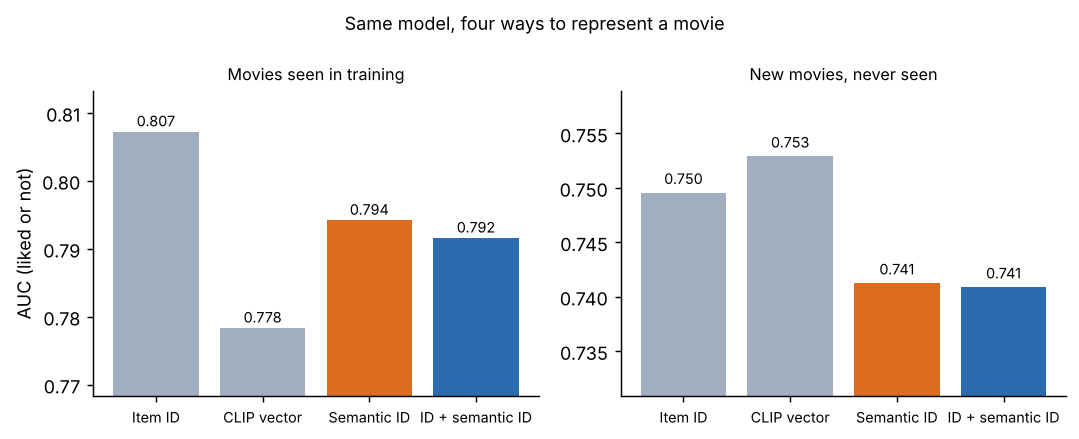

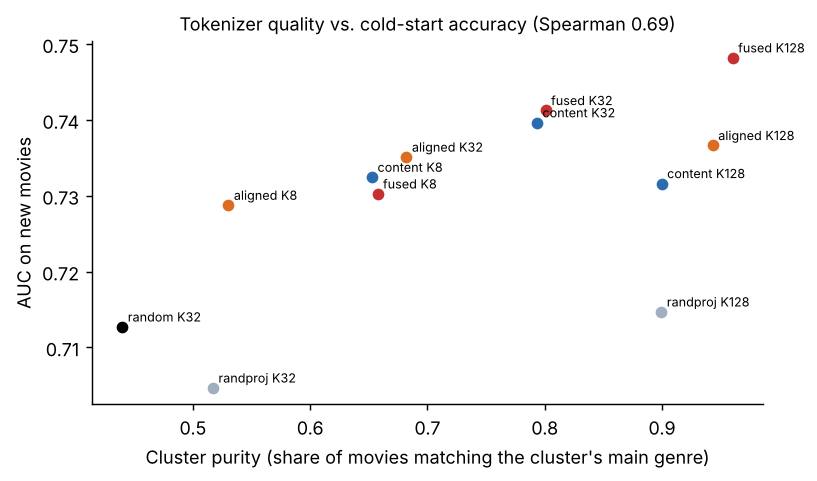

In [9]:
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREY, RED = "#2b6cb0", "#dd6b20", "#a0aec0", "#c53030"
show = [("id", "Item ID"), ("content", "CLIP vector"), (PRIMARY, "Semantic ID"), ("id+sid", "ID + semantic ID")]
fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.4), sharey=False)
for ax, col, title in [(axs[0], "warm", "Movies seen in training"), (axs[1], "cold", "New movies, never seen")]:
    v = [AUC.loc[k, col] for k, _ in show]
    ax.bar([n for _, n in show], v, color=[GREY, GREY, ORANGE, BLUE])
    ax.set_ylim(min(v) - 0.01, max(v) + 0.006); ax.set_title(title, fontsize=9); ax.tick_params(axis="x", labelsize=8)
    for i, x in enumerate(v): ax.text(i, x + 0.0008, f"{x:.3f}", ha="center", fontsize=8)
axs[0].set_ylabel("AUC (liked or not)")
fig.suptitle("Same model, four ways to represent a movie", fontsize=10); fig.tight_layout()
fig.savefig("figures/fig1_auc.png", dpi=200)

fig, ax = plt.subplots(figsize=(6.4, 3.8))
col = {"content": BLUE, "aligned": ORANGE, "fused": RED, "randproj": GREY, "random": "black"}
for k in tok_names:
    ax.scatter(INTR.loc[k, "purity"], AUC.loc[f"sid:{k}", "cold"], color=col[k.split("_")[0]], s=30)
    ax.annotate(k.replace("_", " "), (INTR.loc[k, "purity"], AUC.loc[f"sid:{k}", "cold"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Cluster purity (share of movies matching the cluster's main genre)"); ax.set_ylabel("AUC on new movies")
ax.set_title(f"Tokenizer quality vs. cold-start accuracy (Spearman {RES['H4']['purity']['rho']:.2f})", fontsize=10)
fig.tight_layout(); fig.savefig("figures/fig2_purity_vs_auc.png", dpi=200)

def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
json.dump(clean(RES), open("figures/results.json", "w"), indent=1)

## Scorecard

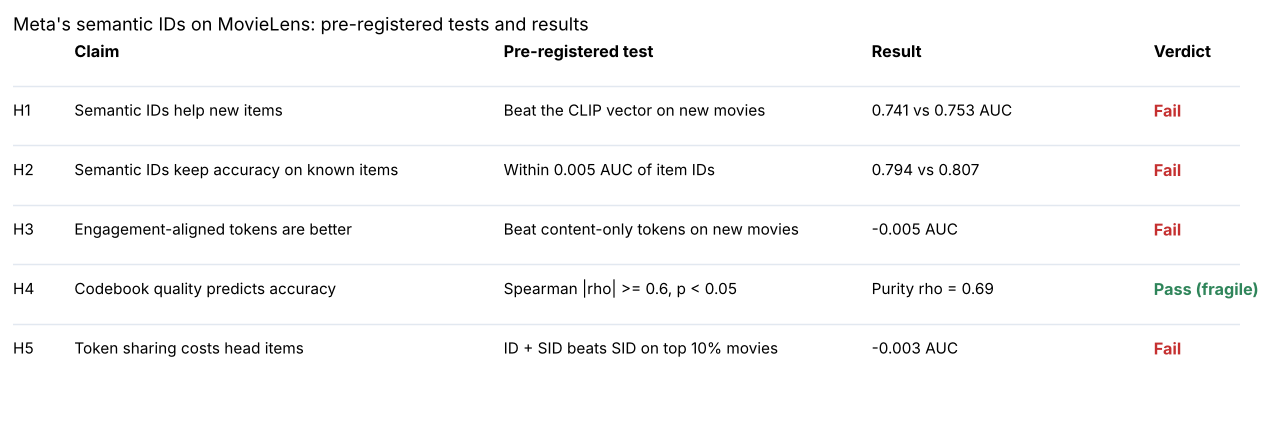

In [10]:
def scorecard(rows, title, path):
    """rows: (id, claim, test, result, verdict). Verdict colors: Pass green, Fail red, other amber."""
    colors = {"Pass": "#2f855a", "Fail": "#c53030"}
    fig, ax = plt.subplots(figsize=(10, 0.48 * len(rows) + 1.0)); ax.axis("off")
    heads = ["", "Claim", "Pre-registered test", "Result", "Verdict"]
    xs = [0.0, 0.05, 0.40, 0.70, 0.93]
    y = 1.0; step = 1.0 / (len(rows) + 1.3)
    for x, h in zip(xs, heads): ax.text(x, y, h, fontsize=9, fontweight="bold", va="top", transform=ax.transAxes)
    for r in rows:
        y -= step
        ax.plot([0, 1], [y + step * 0.25] * 2, color="#e2e8f0", lw=0.8, transform=ax.transAxes)
        for x, t in zip(xs[:4], r[:4]): ax.text(x, y, t, fontsize=8.5, va="top", transform=ax.transAxes, wrap=True)
        ax.text(xs[4], y, r[4], fontsize=9, fontweight="bold", va="top", color=colors.get(r[4].split()[0], "#b7791f"), transform=ax.transAxes)
    ax.set_title(title, fontsize=10, loc="left")
    fig.tight_layout(); fig.savefig(path, dpi=200, bbox_inches="tight")

A2 = AUC
scorecard([
    ("H1", "Semantic IDs help new items", "Beat the CLIP vector on new movies", f"{A2.loc[PRIMARY,'cold']:.3f} vs {A2.loc['content','cold']:.3f} AUC", "Fail"),
    ("H2", "Semantic IDs keep accuracy on known items", "Within 0.005 AUC of item IDs", f"{A2.loc[PRIMARY,'warm']:.3f} vs {A2.loc['id','warm']:.3f}", "Fail"),
    ("H3", "Engagement-aligned tokens are better", "Beat content-only tokens on new movies", f"{RES['H3']['aligned_minus_content_K32']:+.3f} AUC", "Fail"),
    ("H4", "Codebook quality predicts accuracy", "Spearman |rho| >= 0.6, p < 0.05", f"Purity rho = {RES['H4']['purity']['rho']:.2f}", "Pass (fragile)"),
    ("H5", "Token sharing costs head items", "ID + SID beats SID on top 10% movies", f"{RES['H5']['idsid_minus_sid_head']:+.3f} AUC", "Fail"),
], "Meta's semantic IDs on MovieLens: pre-registered tests and results", "figures/fig0_scorecard.png")